This notebook reproduces Fig. 8. The dependence of the fidelity for pulses after a third-order Butterworth filter (see `Fig07-filtered_pulses.ipynb`) on the pulse time is non-trivial. To gain understanding, we compute the minimum infidelity for pulse times $t_\mathrm{f}\in\left[0.1, 20\right]\,\hbar/x$ (panels (a) and (b)) and $t_\mathrm{f}\in\left[1, 30\right]\,\hbar/x$ (panel (c)), including dephasing with $\gamma=0.005\,x/\hbar$, i.e., $T_2=100\,\hbar/x$ (see `Fig02-LZ.ipynb`). Furthermore, we study how this minimum infidelity depends on $n_+$ and the cut-off frequency $f_c$. In panels (a) and (b), $f_c=x/\hbar$. In panel (c), the red dots denote the value of $n_+$ with the minimum infidelity for each cut-off frequency.

To convert to physical units, we use a tunneling rate $x=10\;\mu$eV, such that $x/\hbar\approx 15.2$ GHz and $T_2=100\,\hbar/x\approx 6.6$ ns.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches
from matplotlib.colors import ListedColormap
from parameterrun import parameterrun
from scipy.constants import e, hbar

from HQUAD_lib.physics_utils import fidelity_LZ, filter_pulse
from HQUAD_lib.plotting_utils import add_labels, plot_gradient_lines
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
gamma = 0.005
x = 1
z0 = -10

dynamics_reduction = (
    1  # The filtered pulse has 2 ** 14 + 1 points, as in the manuscript
)

tails_factor = 5

order = 3

# Conversion to physical units
x_ueV = 10
x_GHz = x_ueV * 1e-6 * e / hbar / 1e9  # x / hbar in GHz
print(f"x / hbar = {x_GHz:.1f} GHz, T_2 = {1 / (2 * gamma) / x_GHz:.1f} ns")

x / hbar = 15.2 GHz, T_2 = 6.6 ns


In [3]:
def compute_fidelity_total(
    alpha: float, beta: float, fc: float, tf_list: np.ndarray
) -> np.ndarray:
    z_sol = solve_LZ(alpha, beta, z0=z0, reduction=dynamics_reduction)

    boundary_left = np.ones(len(z_sol) // tails_factor) * z0
    boundary_right = np.ones(len(z_sol) // tails_factor) * -z0
    pulse = np.concatenate((boundary_left, z_sol, boundary_right))

    fidelities = np.zeros(len(tf_list))
    for i in range(len(tf_list)):
        time = np.linspace(0, tf_list[i], len(pulse))
        filtered_pulse = filter_pulse(pulse, time, order=order, fc=fc)
        fidelities[i] = fidelity_LZ(z0, filtered_pulse, tf_list[i], x=x, gamma=gamma)

    return fidelities

# Single $f_c$

In [4]:
fc = 1

n_values = 41  # Increase to enhance resolution (144 values in the manuscript)
n_minus = 0
n_plus = np.linspace(-5, 5, n_values)
n_plus[0] = -np.inf
n_plus[-1] = np.inf

alphas = n_plus + n_minus
betas = n_plus - n_minus

n_tf = 100  # Increase to enhance resolution (500 values in the manuscript)
tf_list = np.linspace(0.1, 20, n_tf) * (1 + 2 / tails_factor)

In [5]:
fidelities = np.asarray(
    parameterrun(
        compute_fidelity_total,
        [["alpha", "beta"]],
        [[alphas, betas]],
        fc=fc,
        tf_list=tf_list,
    )
)

# The total time includes the tails, so the pulse time is rescaled
tf_pulses = tf_list / (1 + 2 / tails_factor)

indices_tilde = np.argmax(fidelities, axis=1)
F_tilde = np.max(fidelities, axis=1)
tf_tilde = tf_pulses[indices_tilde]

compute_fidelity_total: [['alpha', 'beta(...)]:   0%|          | 0/41 [00:00<?, ?it/s]

# Run over $f_c$

In [6]:
n_fc = 30  # Increase to enhance resolution (100 values in the manuscript)
fc_list = np.logspace(-1.5, 0.5, n_fc)

n_values_fc = 51  # Increase to enhance resolution (200 values in the manuscript)
n_plus_fc = np.linspace(0, 5, n_values_fc)
alphas_fc = n_plus_fc + n_minus
betas_fc = n_plus_fc - n_minus

n_tf_fc = 60  # Increase to enhance resolution (200 values in the manuscript)
tf_list_fc = np.linspace(1, 30, n_tf_fc) * (1 + 2 / tails_factor)

In [7]:
fidelities_fc = np.asarray(
    parameterrun(
        compute_fidelity_total,
        [["alpha", "beta"], ["fc"]],
        [[alphas_fc, betas_fc], [fc_list]],
        tf_list=tf_list_fc,
    )
)
fidelities_fc = fidelities_fc.reshape((n_values_fc, n_fc, n_tf_fc))

optimal_max_fidelity = np.max(fidelities_fc, axis=-1)

compute_fidelity_total: [['alpha', 'beta(...)]:   0%|          | 0/1530 [00:00<?, ?it/s]

# Plot

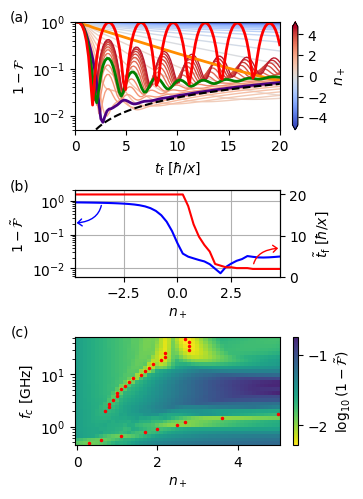

In [8]:
cmap_fidelity = ListedColormap(mpl.colormaps["viridis_r"](np.linspace(0, 0.9, 256)))

fig, axs = plt.subplots(
    3, 1, figsize=(3.3, 5.5), gridspec_kw={"height_ratios": [1, 0.8, 1]}
)

# (a) Infidelities
_, sm, _ = plot_gradient_lines(
    tf_pulses,
    1 - fidelities,
    alphas,
    betas,
    x_label=r"$t_\mathrm{f}\; [\hbar / x]$",
    y_label=r"$1 - \mathcal{F}$",
    ax=axs[0],
    legend_bool=False,
    cbar_bool=False,
)

cbar = plt.colorbar(sm, ax=axs[0], label=r"$n_+ $", location="right", extend="both")
cbar.ax.set_yticks([-4, -2, 0, 2, 4])

axs[0].plot(tf_pulses, 1 / 2 * (1 - np.exp(-tf_pulses * gamma)), ls="--", c="k")
axs[0].set_yscale("log")
axs[0].set_ylim(5e-3, 1)
axs[0].set_xlim(0, 20)

# (b) Minimum infidelity and optimal pulse time. An invisible colorbar keeps the width of the panels
cbar = plt.colorbar(sm, ax=axs[1], location="right")
cbar.remove()

colors = ["b", "r"]
axs[1].plot(n_plus, 1 - F_tilde, c=colors[0])
axs[1].set_yscale("log")
axs[1].grid()

axs[1].set_xlim(np.min(n_plus[1:-1]), np.max(n_plus[1:-1]))
axs[1].set_ylim(None, 2)
axs[1].set_ylabel(r"$1 - \tilde{\mathcal{F}}$")
axs[1].set_xlabel(r"$n_+$")

ax2 = axs[1].twinx()
ax2.plot(n_plus, tf_tilde, c=colors[1])
ax2.set_ylabel(r"$\tilde{t}_\mathrm{f} \; [\hbar / x]$")
ax2.set_ylim(0, 21)

for start, end, color in [
    ((-3.5, 19), (-5, 13), colors[0]),
    ((3.5, 1.5), (5, 7), colors[1]),
]:
    ax2.add_patch(
        patches.FancyArrowPatch(
            start,
            end,
            connectionstyle="angle3,angleA=90,angleB=0",
            shrinkA=5,
            shrinkB=5,
            arrowstyle="->, head_width=2.5, head_length=3",
            color=color,
            clip_on=False,
        )
    )

# (c) Minimum infidelity versus the cut-off frequency
im = axs[2].pcolormesh(
    n_plus_fc,
    fc_list * x_GHz,
    np.log10(1 - optimal_max_fidelity.T),
    cmap=cmap_fidelity,
    linewidth=0,
    rasterized=True,
)

axs[2].set_xlabel(r"$n_+$")
axs[2].set_ylabel(r"$f_c$ [GHz]")
axs[2].set_yscale("log")

plt.colorbar(im, ax=axs[2], label=r"$\log_{10}(1 - \tilde{\mathcal{F}})$")

# Optimal n_+ for each cut-off frequency
best_n_plus = n_plus_fc[np.argmax(optimal_max_fidelity, axis=0)]
axs[2].plot(best_n_plus, fc_list * x_GHz, "r.", markersize=3)

fig.subplots_adjust(hspace=0.6)
add_labels(axs, [-0.27, 1.05])